# VESTIGIUM | Data Engineering Walkthrough

**NASA Space Apps Challenge 2026 · Team Ga Tidur**

This notebook reads the **outputs** from `build_pipeline.py`. It does not re-process 6 million CSV rows in-memory. It verifies contracts, explores lineage, and demonstrates the query shapes required by the map and temporal dashboard. All dates are UTC; all recorded fires are satellite *detections*, not confirmed fire events.

## 1. Setup and reproducibility

Run the pipeline first:

```bash
python build_pipeline.py --input ../data.zip --output ./outputs
```

Place this notebook next to `build_pipeline.py`. The output directory can be changed below.

In [1]:
from pathlib import Path
import sqlite3, json, csv
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path('outputs')
DB = DATA_DIR / 'vestigium_hotspots.sqlite'
QA = json.loads((DATA_DIR / 'quality_report.json').read_text())
assert DB.exists(), 'Run build_pipeline.py first'
print('Archive SHA-256:', QA['input_sha256'])
print('Detected rows:', QA['accepted_presumed_vegetation_detections'])
print('Skipped non-vegetation:', QA['excluded_non_vegetation_detections'])
print('Rejected invalid rows:', QA['rejected_invalid_rows'])

Archive SHA-256: 8af7ff723b8d5c0916b382b1a2f9088b9028b75fecc1c2cfb927831c1127bcba
Detected rows: 5997676
Skipped non-vegetation: 357858
Rejected invalid rows: 0


## 2. Data provenance, schema, and sensor inventory

All input CSVs are hashed and retained in `source_files`. Satellite confidence is intentionally split into `confidence_modis_pct` and `confidence_viirs_label`.

In [2]:
con=sqlite3.connect(f'file:{DB.resolve()}?mode=ro', uri=True)
files=pd.read_sql_query("""SELECT sensor, nominal_year, filename, source_rows, accepted_type0, excluded_non_vegetation,
 rejected_invalid, first_date_utc, last_date_utc FROM source_files ORDER BY sensor,nominal_year""",con)
display(files.head(8))
print('Input files:', len(files))
print(files.groupby('sensor')[['source_rows','accepted_type0','excluded_non_vegetation','rejected_invalid']].sum())

,sensor,nominal_year,filename,source_rows,accepted_type0,excluded_non_vegetation,rejected_invalid,first_date_utc,last_date_utc
0,MODIS,2000,MODIS/modis_2000_Indonesia.csv,691,594,97,0,2000-11-01,2000-12-31
1,MODIS,2001,MODIS/modis_2001_Indonesia.csv,15078,13736,1342,0,2001-01-01,2001-12-31
2,MODIS,2002,MODIS/modis_2002_Indonesia.csv,123327,120781,2546,0,2002-01-01,2002-12-31
3,MODIS,2003,MODIS/modis_2003_Indonesia.csv,62751,60545,2206,0,2003-01-01,2003-12-31
4,MODIS,2004,MODIS/modis_2004_Indonesia.csv,107117,103390,3727,0,2004-01-01,2004-12-31
5,MODIS,2005,MODIS/modis_2005_Indonesia.csv,74797,64369,10428,0,2005-01-01,2005-12-31
6,MODIS,2006,MODIS/modis_2006_Indonesia.csv,154985,147458,7527,0,2006-01-01,2006-12-30
7,MODIS,2007,MODIS/modis_2007_Indonesia.csv,43224,41945,1279,0,2007-01-01,2007-12-31


Input files: 48
              source_rows  ...  rejected_invalid
sensor                     ...                  
MODIS             1533411  ...                 0
VIIRS_NOAA20      1307603  ...                 0
VIIRS_SNPP        3514520  ...                 0

[3 rows x 4 columns]


## 3. Full quality gate reconciliation

Counts must reconcile across the ingestion ledger, the individual points table and each summary. This guards against silent row multiplication or dropping rows during grouping.

In [3]:
db_count=con.execute('SELECT COUNT(*) FROM hotspots').fetchone()[0]
assert db_count == QA['accepted_presumed_vegetation_detections']
for filename in ['daily_sensor.csv','monthly_sensor.csv','annual_sensor.csv','monthly_grid.csv','annual_grid.csv']:
    table=pd.read_csv(DATA_DIR/filename)
    assert int(table['detection_count'].sum()) == db_count, filename
    print(filename, len(table), 'groups; reconciles:', int(table['detection_count'].sum()))
print('PASS: all five groups reconcile with', db_count, 'detection rows')

daily_sensor.csv 16880 groups; reconciles: 5997676
monthly_sensor.csv 563 groups; reconciles: 5997676
annual_sensor.csv 48 groups; reconciles: 5997676


monthly_grid.csv 432387 groups; reconciles: 5997676
annual_grid.csv 104359 groups; reconciles: 5997676
PASS: all five groups reconcile with 5997676 detection rows


## 4. Annual detection history, separated by sensor

These are **not** unique fire events and their absolute counts are not directly comparable across sensors, because spatial resolution, observing conditions and overpass frequency differ.

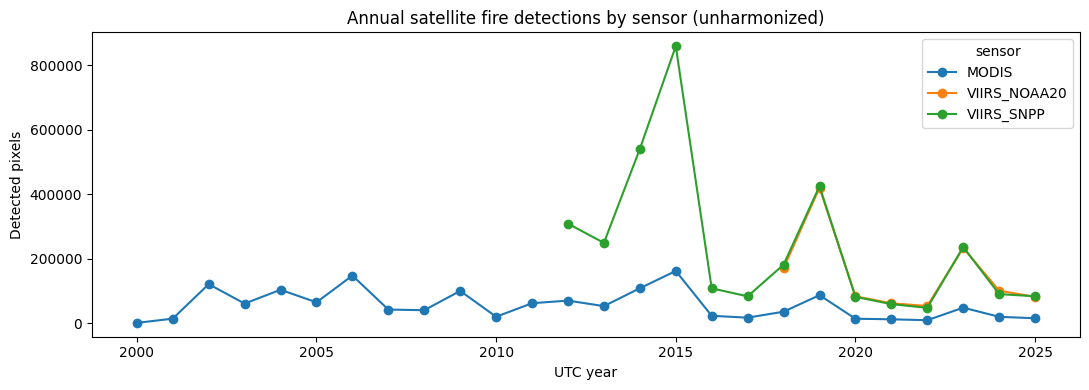

In [4]:
annual=pd.read_csv(DATA_DIR/'annual_sensor.csv')
pivot=annual.pivot(index='year',columns='sensor',values='detection_count')
ax=pivot.plot(figsize=(11,4),marker='o',linewidth=1.5)
ax.set(title='Annual satellite fire detections by sensor (unharmonized)', ylabel='Detected pixels',xlabel='UTC year')
plt.tight_layout();plt.show()

## 5. Monthly history and seasonality

Missing month rows may mean no detections or incomplete observations. The pipeline does **not** invent zeros in the source.

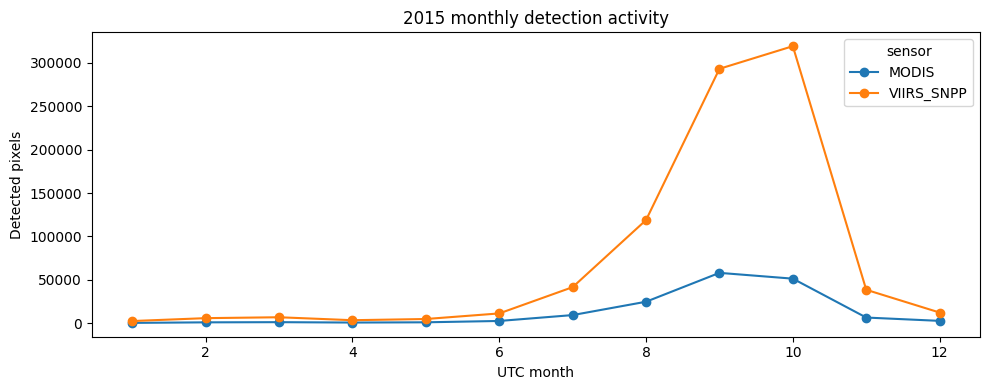

In [5]:
monthly=pd.read_csv(DATA_DIR/'monthly_sensor.csv')
sample=monthly[monthly['year']==2015]
ax=sample.pivot(index='month',columns='sensor',values='detection_count').plot(kind='line',marker='o',figsize=(10,4))
ax.set(title='2015 monthly detection activity',xlabel='UTC month',ylabel='Detected pixels')
plt.tight_layout();plt.show()

## 6. Grid aggregation sanity check

The map grid is fixed at **0.25 degrees**. Center points are display locations for groups and must not be mistaken for a detected fire's exact pixel centroid.

Active 2015 MODIS cells: 2461
Annual total matches: 161757 161757


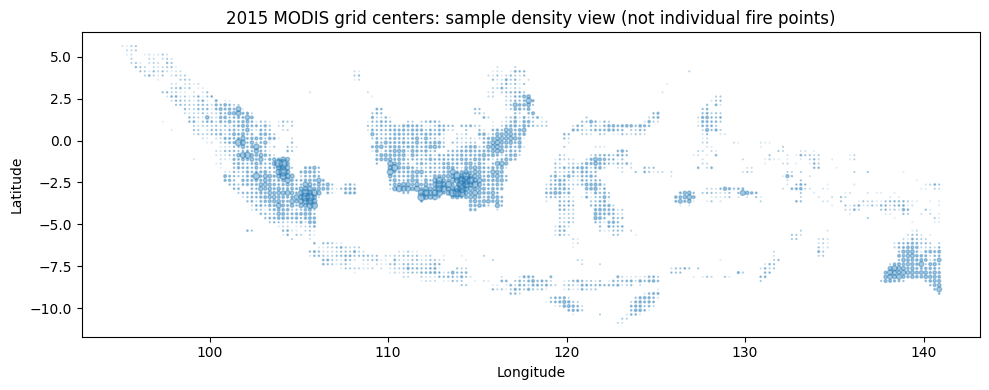

In [6]:
grid=pd.read_csv(DATA_DIR/'annual_grid.csv')
grid2015=grid[(grid.year==2015)&(grid.sensor=='MODIS')]
print('Active 2015 MODIS cells:', len(grid2015))
print('Annual total matches:',grid2015.detection_count.sum(),annual.query("sensor=='MODIS' and year==2015").detection_count.iloc[0])
ax=grid2015.plot.scatter(x='grid_center_lon',y='grid_center_lat',s=grid2015.detection_count.clip(1,1000)/30,alpha=.4,figsize=(10,4))
ax.set(title='2015 MODIS grid centers: sample density view (not individual fire points)',xlabel='Longitude',ylabel='Latitude')
plt.tight_layout();plt.show()

## 7. Individual detections for hover payloads

Spatially restricted SQL protects the browser from millions of points. The dashboard should use clustering or grid aggregates when zoomed out.

In [7]:
from example_queries import fetch_hotspots
spots=fetch_hotspots(str(DB),2015,9,108,-4,119,4,limit=10,sensor='MODIS')
display(pd.DataFrame(spots))

,latitude,longitude,date_utc,time_utc,timestamp_utc,sensor,satellite,frp_mw,confidence_modis_pct,confidence_viirs_label,daynight
0,1.9790,117.2244,2015-09-01,0309,2015-09-01T03:09:00Z,MODIS,Terra,35.9,69,None,D
1,1.9671,117.2386,2015-09-01,0309,2015-09-01T03:09:00Z,MODIS,Terra,54.8,72,None,D
2,-0.0231,116.3549,2015-09-01,0310,2015-09-01T03:10:00Z,MODIS,Terra,16.6,58,None,D
3,-1.1123,110.6280,2015-09-01,0310,2015-09-01T03:10:00Z,MODIS,Terra,5.0,58,None,D
4,-0.2711,110.5452,2015-09-01,0310,2015-09-01T03:10:00Z,MODIS,Terra,13.0,73,None,D
5,-0.3872,111.2091,2015-09-01,0310,2015-09-01T03:10:00Z,MODIS,Terra,28.3,85,None,D
6,-0.3885,111.2184,2015-09-01,0310,2015-09-01T03:10:00Z,MODIS,Terra,17.1,78,None,D
7,-0.1178,111.5611,2015-09-01,0310,2015-09-01T03:10:00Z,MODIS,Terra,8.3,62,None,D
8,-0.1192,111.5706,2015-09-01,0310,2015-09-01T03:10:00Z,MODIS,Terra,7.0,55,None,D
9,-1.4745,111.1525,2015-09-01,0310,2015-09-01T03:10:00Z,MODIS,Terra,10.8,70,None,D


## 8. Sensor confidence semantic checks

MODIS uses a numerical 0–100 confidence scale; VIIRS uses categorical `l/n/h`. Mixing them as a single numerical predictor would be scientifically unsound.

In [8]:
assert con.execute("SELECT COUNT(*) FROM hotspots WHERE sensor='MODIS' AND confidence_viirs_label IS NOT NULL").fetchone()[0] == 0
assert con.execute("SELECT COUNT(*) FROM hotspots WHERE sensor LIKE 'VIIRS%' AND confidence_modis_pct IS NOT NULL").fetchone()[0] == 0
print('Sensor-specific confidence storage: PASS')

Sensor-specific confidence storage: PASS


## 9. Connection to NASA harmonization and social impact module

This ETL is **not** sensor harmonization. It provides provenance, temporal records, spatial bins and a stable query substrate. The next step is comparing overlapping MODIS/VIIRS observation windows with coverage corrections and held-out evaluation. The data do **not** provide trustworthy labels for intentional vs natural ignition.

For long-term land changes, add distinct area-burned and land-cover products, including spatial overlays and documented time-alignment uncertainty. Do not treat a hotspot point as a burned-area polygon.

In [9]:
con.close()
print('Completed VESTIGIUM Data Engineering walkthrough.')

Completed VESTIGIUM Data Engineering walkthrough.
